In [ ]:
n liquid phase reactor the reaction A+B gives c initial concentration are A =1 , B= 1, C= 0 if x mol/l of C is formed Kc=x/(1-x)^2 which rearrange to a quadratic equation. Kcx^2-(2Kc+1)^2 X +1 =0 write the python program that 1.read the Kc using the input 2.find a,b,c using discriminant and both roots 3. select the physically meaningful roots (0<=x<=1)   4.prints equlibrium A,B,C (# decimal)  5. classifires the conversion using if /elif/else: =>70% high, =>40%  moderate, otherwise low

In [13]:
# Equilibrium solver for A + B <-> C, with initial concentrations [A]0 = [B]0 = 1 mol/L
kc = float(input("Enter the equilibrium constant Kc: "))

if kc < 0:
    raise ValueError("Kc must be non-negative.")

# From Kc = x / (1 - x)^2:
# Kc*x^2 - (2*Kc + 1)*x + Kc = 0
a = kc
b = -(2 * kc + 1)
c = kc

discriminant = b**2 - 4 * a * c
print(f"a = {a}, b = {b}, c = {c}")
print(f"Discriminant = {discriminant}")

if a == 0:
    # When Kc is zero, the equation reduces to -x = 0.
    roots = [-c / b]
    print(f"Root: {roots[0]:.6f}")
elif discriminant < 0:
    roots = []
    print("There are no real roots.")
else:
    sqrt_discriminant = discriminant**0.5
    root1 = (-b + sqrt_discriminant) / (2 * a)
    root2 = (-b - sqrt_discriminant) / (2 * a)
    roots = [root1, root2]
    print(f"Roots: {root1:.6f}, {root2:.6f}")

physical_roots = [root for root in roots if 0 <= root <= 1]
if not physical_roots:
    raise ValueError("No physically meaningful root in the range 0 <= x <= 1.")

x = physical_roots[0]
print(f"Physically meaningful root x = {x:.3f} mol/L")

concentration_a = 1 - x
concentration_b = 1 - x
concentration_c = x
print(f"Equilibrium [A] = {concentration_a:.3f} mol/L")
print(f"Equilibrium [B] = {concentration_b:.3f} mol/L")
print(f"Equilibrium [C] = {concentration_c:.3f} mol/L")

conversion_percent = x * 100
print(f"Conversion = {conversion_percent:.2f}%")
if conversion_percent >= 70:
    print("Conversion is high.")
elif conversion_percent >= 40:
    print("Conversion is moderate.")
else:
    print("Conversion is low.")

a = 0.5, b = -2.0, c = 0.5
Discriminant = 3.0
Roots: 3.732051, 0.267949
Physically meaningful root x = 0.268 mol/L
Equilibrium [A] = 0.732 mol/L
Equilibrium [B] = 0.732 mol/L
Equilibrium [C] = 0.268 mol/L
Conversion = 26.79%
Conversion is low.


In [ ]:
Part A : A batch reactor decomposes reactant A (A  gives product) by first order reaction, dc/dt = -kC. use the euler method: C_new = C_old-k.C_old.dt. Take Co = 2 mol/L, k = 0.08 /min, dt = 1 min. find 1. using a loop for stimulate 10 min and print the table of time in min, Concentration (Mol/L) , Conversion%   2.  Using math.exp(), Calculate the exact value Coe^9(-Kt) at 10 min, and print the absolute error of euler result.  3. Using the While loop , repeat the stimulation until conversion reches 60% or time reaches 100 min. print the time needed and the final Concentration                                       

In [14]:
# Part A: First-order decomposition of A using Euler's method
import math

initial_concentration = 2.0  # mol/L
rate_constant = 0.08  # 1/min
time_step = 1.0  # min

# Euler simulation for 10 minutes
concentration = initial_concentration
print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{0:>4}\t\t{concentration:>10.4f}\t\t{0.0:>10.2f}")

for time_min in range(1, 11):
    concentration = concentration - rate_constant * concentration * time_step
    conversion_percent = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time_min:>4}\t\t{concentration:>10.4f}\t\t{conversion_percent:>10.2f}")

euler_concentration_10min = concentration
exact_concentration_10min = initial_concentration * math.exp(-rate_constant * 10)
absolute_error = abs(euler_concentration_10min - exact_concentration_10min)
print(f"\nEuler concentration at 10 min: {euler_concentration_10min:.6f} mol/L")
print(f"Exact concentration at 10 min: {exact_concentration_10min:.6f} mol/L")
print(f"Absolute error at 10 min: {absolute_error:.6f} mol/L")

# Continue with Euler's method until conversion reaches 60% or time reaches 100 min
concentration = initial_concentration
time_min = 0
conversion_percent = 0.0

while conversion_percent < 60 and time_min < 100:
    concentration = concentration - rate_constant * concentration * time_step
    time_min += 1
    conversion_percent = (initial_concentration - concentration) / initial_concentration * 100

print(f"\nTime to reach 60% conversion (or 100 min): {time_min} min")
print(f"Final concentration: {concentration:.6f} mol/L")
print(f"Final conversion: {conversion_percent:.2f}%")

Time (min)	Concentration (mol/L)	Conversion (%)
   0		    2.0000		      0.00
   1		    1.8400		      8.00
   2		    1.6928		     15.36
   3		    1.5574		     22.13
   4		    1.4328		     28.36
   5		    1.3182		     34.09
   6		    1.2127		     39.36
   7		    1.1157		     44.22
   8		    1.0264		     48.68
   9		    0.9443		     52.78
  10		    0.8688		     56.56

Euler concentration at 10 min: 0.868777 mol/L
Exact concentration at 10 min: 0.898658 mol/L
Absolute error at 10 min: 0.029881 mol/L

Time to reach 60% conversion (or 100 min): 11 min
Final concentration: 0.799275 mol/L
Final conversion: 60.04%


In [ ]:
Part B : Batch lable such as PLANT20261030 are stored as text . Write a program that reads a lable, loops throuh each character and prints the number of digits and ths sum of the digits. Show a message for an empty lable and for a lable with no digits. Teest with PLANT20261030, AN empty lable and ABCDEF

In [32]:
# Part B: Count and sum digits in a batch label
def analyze_batch_label(label):
    if label == "":
        print("The batch label is empty.")
        return

    digit_count = 0
    digit_sum = 0

    for character in label:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print(f"Label: {label} | No digits found.")
    else:
        print(f"Label: {label} | Number of digits: {digit_count} | Sum of digits: {digit_sum}")


# Test the requested labels
for test_label in ["PLANT20261030", "", "ABCDEF"]:
    analyze_batch_label(test_label)

# Read and analyze another label entered by the user
user_label = input("Enter a batch label: ")
analyze_batch_label(user_label)

Label: PLANT20261030 | Number of digits: 8 | Sum of digits: 14
The batch label is empty.
Label: ABCDEF | No digits found.
Label: ABCDEF | No digits found.


In [ ]:
PART A : A laboratory has n candidates additives and wants to test r of them together in one formulation . write the recursive function factorial(n) and a function combination(n,r)=n!/(r!(n-r)!) that uses it. Reject the invalid input(negative values, r>n). Print the number of possible formulation for n= 6, r=3 and show the message for n = 56, r = 7

In [33]:
# Part A: Recursive combinations for selecting additives
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if n < 0:
        raise ValueError("Factorial is not defined for negative integers.")
    if n <= 1:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if not isinstance(r, int) or isinstance(r, bool):
        raise TypeError("r must be an integer.")
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


n, r = 6, 3
print(f"For n = {n} and r = {r}, possible formulations = {combination(n, r)}")

n, r = 56, 7
print(f"For n = {n} and r = {r}, possible formulations = {combination(n, r)}")

For n = 6 and r = 3, possible formulations = 20
For n = 56 and r = 7, possible formulations = 231917400


In [ ]:
Part B: During the reaaction, Samples are taken at time = Fibonacci number*2 min. Write an iterative function fib_iter(n) that return the list of the first n fibonacci number, and a recursive function fib_rec(k) that returns the Kth Fibonacci number (Fo = 0, F1 = 1). for n = 10 , check that both functions agree and print a table: Sample No. | Fibonacci tag | Sampling time(min)

In [34]:
# Part B: Fibonacci-tagged sampling times
def fib_iter(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise TypeError("n must be an integer.")
    if n < 0:
        raise ValueError("n must be non-negative.")

    fibonacci_numbers = []
    previous, current = 0, 1
    for _ in range(n):
        fibonacci_numbers.append(previous)
        previous, current = current, previous + current
    return fibonacci_numbers


def fib_rec(k):
    if not isinstance(k, int) or isinstance(k, bool):
        raise TypeError("k must be an integer.")
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k <= 1:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
iterative_values = fib_iter(n)
recursive_values = [fib_rec(k) for k in range(n)]

if iterative_values != recursive_values:
    raise AssertionError("The iterative and recursive Fibonacci values do not match.")

print("Check passed: iterative and recursive Fibonacci values agree.")
print("Sample No. | Fibonacci tag | Sampling time (min)")
for sample_number, (fibonacci_index, fibonacci_value) in enumerate(
    enumerate(iterative_values), start=1
):
    sampling_time = fibonacci_value * 2
    print(f"{sample_number:>10} | F{fibonacci_index} = {fibonacci_value:<7} | {sampling_time:>19}")

Check passed: iterative and recursive Fibonacci values agree.
Sample No. | Fibonacci tag | Sampling time (min)
         1 | F0 = 0       |                   0
         2 | F1 = 1       |                   2
         3 | F2 = 1       |                   2
         4 | F3 = 2       |                   4
         5 | F4 = 3       |                   6
         6 | F5 = 5       |                  10
         7 | F6 = 8       |                  16
         8 | F7 = 13      |                  26
         9 | F8 = 21      |                  42
        10 | F9 = 34      |                  68


In [35]:
pip install pandas matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
Volume_L': [1.0, 2, 3.0, 4.0, 5],
    'Pressure_bar': [4.00,2.03, 1.31, 1.02, 0.81]
plot pressure vs volume as a scatter plot. Calculate k as the mean of p*v and draw3 the reference curve p = k/v on the same graph. add title , lables with units and legends

Mean PV constant, k = 4.024 bar L


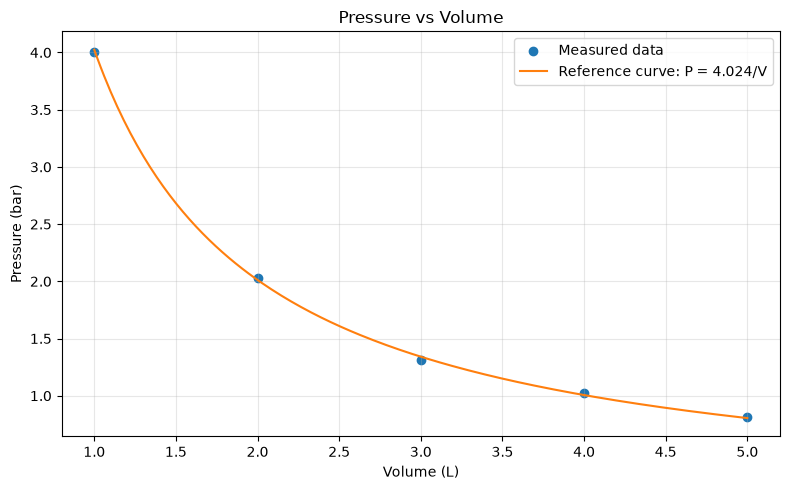

In [37]:
import matplotlib.pyplot as plt
import numpy as np

volumes_l = [1.0, 2, 3.0, 4.0, 5]
pressures_bar = [4.00, 2.03, 1.31, 1.02, 0.81]

pv_products = [volume * pressure for volume, pressure in zip(volumes_l, pressures_bar)]
k = sum(pv_products) / len(pv_products)
print(f"Mean PV constant, k = {k:.3f} bar L")

reference_volumes = np.linspace(min(volumes_l), max(volumes_l), 200)
reference_pressures = [k / volume for volume in reference_volumes]

plt.figure(figsize=(8, 5))
plt.scatter(volumes_l, pressures_bar, color="tab:blue", label="Measured data")
plt.plot(reference_volumes, reference_pressures, color="tab:orange", label=f"Reference curve: P = {k:.3f}/V")
plt.title("Pressure vs Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 